### Downstream analysis FUNPROFILER, module: func_classification_rb
Raw reads count are aggregated for all the samples using the geomosaic command:
```bash
geomosaic gather -s gmsetup -p funprofiler
```

In [35]:
# Imports
library(phyloseq)
library(readr)
library(dplyr)
library(tidyr)
library(stringr)
library(ggplot2)
library(tidyverse)


options(readr.show_col_types = FALSE)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ purrr     1.2.2
✔ lubridate 1.9.5     ✔ tibble    3.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
theme_glab <- function(base_size = 11, base_family = "") {
  theme_bw(base_size = base_size, base_family = base_family) %+replace%
    theme(
      legend.background = element_blank(),
      legend.title      = element_text(
        color = rgb(100, 100, 100, maxColorValue = 255),
        size = rel(0.65),
        hjust = 0
      ),
      legend.text       = element_text(
        color = rgb(100, 100, 100, maxColorValue = 255),
        size = rel(0.65)
      ),
      legend.key.size   = unit(0.8, "lines"),
      plot.title        = element_text(
        color = rgb(100, 100, 100, maxColorValue = 255),
        hjust = 0.5, 
        face = "bold"
      ),
      axis.title        = element_text(
        color = rgb(100, 100, 100, maxColorValue = 255),
        size = rel(0.65)
      ),
      axis.text         = element_text(
        color = rgb(100, 100, 100, maxColorValue = 255),
        size = rel(0.65)
      ),
      panel.grid.major  = element_blank(),
      panel.grid.minor  = element_blank(),
      panel.border      = element_rect(
        fill = NA,
        colour = rgb(100, 100, 100, maxColorValue = 255)
      ),
      complete = TRUE
    )
}

In [6]:
file <- "../tables/gm_gathering/funprofiler/raw_counts_intersect_bp.tsv"

read_funcprofiler <- function(file) {
  otu <- as.data.frame(read_delim(paste0(file),
    delim = "\t"
    ))
    #otu$ID <- paste0("", seq_len(nrow(otu)))
  rownames(otu) <- otu$ko_id
  otu_num <- otu[, -1]
  return(data.frame(otu_num))
}

In [8]:
otu <- read_funcprofiler(file)

In [9]:
head(otu)

,CR18_ER180415_F,CR18_ER180415_S,CR18_LE180416_F,CR18_LE180416_S,CR18_XF180416_F,CR18_XF180416_S,CR18_LW180405_F,CR18_LW180405_S
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
K00001,11000,10000,13000,8000,15000,6000,0,4000
K00002,0,0,0,0,0,1000,0,0
K00003,36000,27000,41000,28000,46000,19000,4000,11000
K00004,13000,4000,5000,3000,6000,5000,1000,5000
K00005,1000,1000,2000,0,4000,0,0,0
K00007,1000,1000,1000,1000,1000,1000,0,1000


In [37]:
taxa <- as.data.frame(read_delim("../tables/subset_biogeochemical_data.tsv",
                    delim = '\t',  # Note: read.delim uses 'sep', read_delim uses 'delim'
                    locale = locale(decimal_mark = ",")
                    ))


In [31]:
unique(taxa$KO[duplicated(taxa$KO)])


[1] "K00371" "K00368" "K15864" "K10944" "K10945" "K10946" "K00370"

In [50]:
biogeo <- read_tsv("../tables/subset_biogeochemical_data.tsv", show_col_types = FALSE) %>%
  mutate(across(where(is.character), str_squish))      # fixes \r, double spaces

ko_annot <- biogeo %>%
  group_by(KO) %>%
  summarise(
    across(everything(), ~ paste(unique(.x), collapse = " | ")),
    n_pathways = n(),
    .groups = "drop"
  ) %>%
  mutate(multi_pathway = n_pathways > 1) %>%
  column_to_rownames("KO")

any(duplicated(rownames(ko_annot)))   # FALSE -> KOs are unique

[1] FALSE

In [51]:
head(rownames(ko_annot))
ko_annot[1:5, 1:3]

[1] "K00116" "K00158" "K00164" "K00184" "K00185" "K00193"

,Element,Relevance,Cycle
,<chr>,<chr>,<chr>
K00116,Carbon,Biogeochemistry,Heterotrophy
K00158,Oxygen,Biogeochemistry,Oxygen respiration
K00164,Carbon,Biogeochemistry,Heterotrophy
K00184,Sulfur,Biogeochemistry,Sulfur
K00185,Sulfur,Biogeochemistry,Sulfur


In [52]:
env <- as.data.frame(read_delim("../tables/cr18_env_geomosaicPlot.csv",
                  delim = ",",
                  skip = 1,
                  locale = locale(decimal_mark = ",")))

rownames(env) <- env$Geomosaic_sample

# Generating Phyloseq Object
phy <- phyloseq(
  otu_table(as.matrix(otu), taxa_are_rows = T),
  tax_table(as.matrix(ko_annot)),
  sample_data(env)
)

In [ ]:
# Normalize counts to relative abundance first and then multiply for the median library abundance
func_ndata_ra <- transform_sample_counts(phy, function(x) ((x / sum(x, na.rm=T))*median(colSums(otu_table(phy), na.rm=T))))
# func_ndata_ra <- transform_sample_counts(phy, function(x) x/sum(x) * 100 )

In [61]:
# Transform the normalized counts to relative for the barplot
func_ndata_ra_norm <- transform_sample_counts(func_ndata_ra, function(x) ((x / sum(x, na.rm=T))))

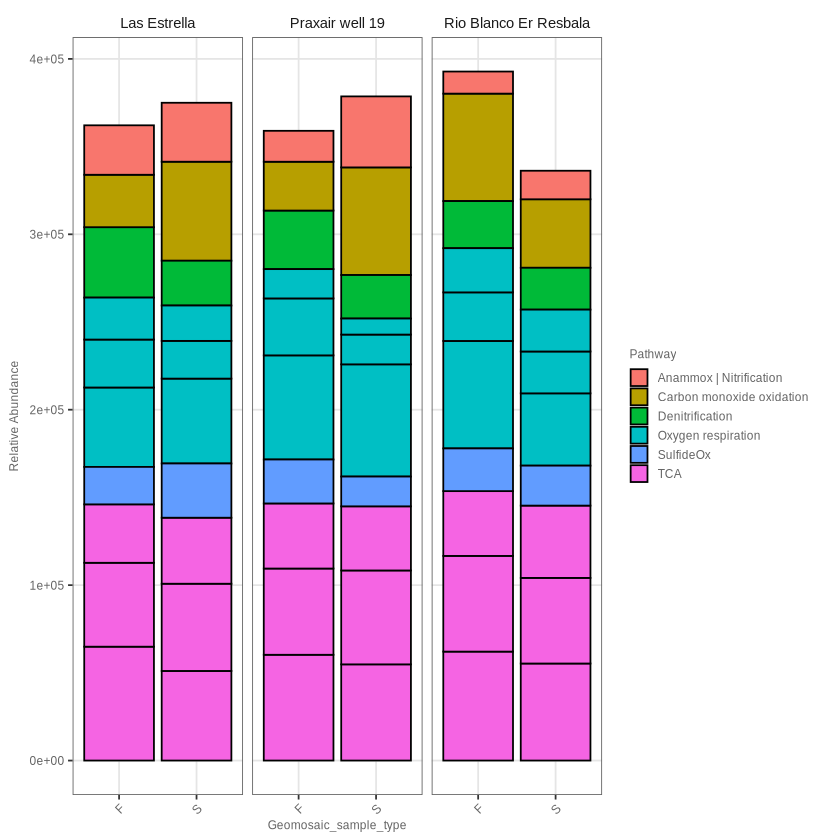

In [63]:
N <- 10

top10.genes <- sort(taxa_sums(func_ndata_ra_norm), decreasing = TRUE)[1:N]
func.top10.ra <- prune_taxa(names(top10.genes), func_ndata_ra)

plot_bar(func.top10.ra, x = "Geomosaic_sample_type", fill="Pathway") +
  facet_grid(~site_name, scales = "free", space = "free") +
  labs(y = "Relative Abundance") +
  theme_glab() +
  theme(
    axis.text.x = element_text(angle = 45, vjust = 1, hjust = 1),
    strip.text.y = element_blank(),  # Rimuove il testo delle righe del facet_grid
    strip.background = element_blank(),  # Rimuove il box di background delle righe del facet_grid
    legend.position = "right",
    panel.grid.major = element_line(color = "grey90")
  )

In [64]:
# ---- Ensure all values are numeric ----
# Converts every column to numeric (in case they were read as characters)
otu[] <- lapply(otu, as.numeric)

# ---- Define helper function to calculate total rpoB abundance ----
# The rpoB total per sample is computed as:
#   sum(K03043, K13797) + mean(K03044, K03045) + K13798
get_rpoB_total <- function(df) {
  
  # Ensure numeric
  df[] <- lapply(df, as.numeric)
  
  # List of required KO identifiers for rpoB
  required_genes <- c("K03043", "K13797", "K03044", "K03045", "K13798")
  present_genes <- rownames(df)
  
  # Check that required genes are present
  missing <- setdiff(required_genes, present_genes)
  if (length(missing) > 0) {
    warning("Missing rpoB genes in table: ", paste(missing, collapse = ", "))
  }
  
  # Calculate rpoB total per sample
  total <- rep(0, ncol(df))
  
  if (all(c("K03043", "K13797") %in% present_genes))
    total <- total + colSums(df[c("K03043", "K13797"), , drop = FALSE], na.rm = TRUE)
  
  if (all(c("K03044", "K03045") %in% present_genes))
    total <- total + colMeans(df[c("K03044", "K03045"), , drop = FALSE], na.rm = TRUE)
  
  if ("K13798" %in% present_genes)
    total <- total + as.numeric(df["K13798", , drop = TRUE])
  
  return(total)
}

# ---- Normalize OTU table by rpoB totals ----
# Each sample is divided by its corresponding rpoB total
otu_rpo <- sweep(otu, 2, get_rpoB_total(otu), "/")

cat("otu_rpo:", nrow(otu_rpo), "rows,", ncol(otu_rpo), "samples\n")

otu_rpo: 8048 rows, 8 samples


## Genes normalized by RPO

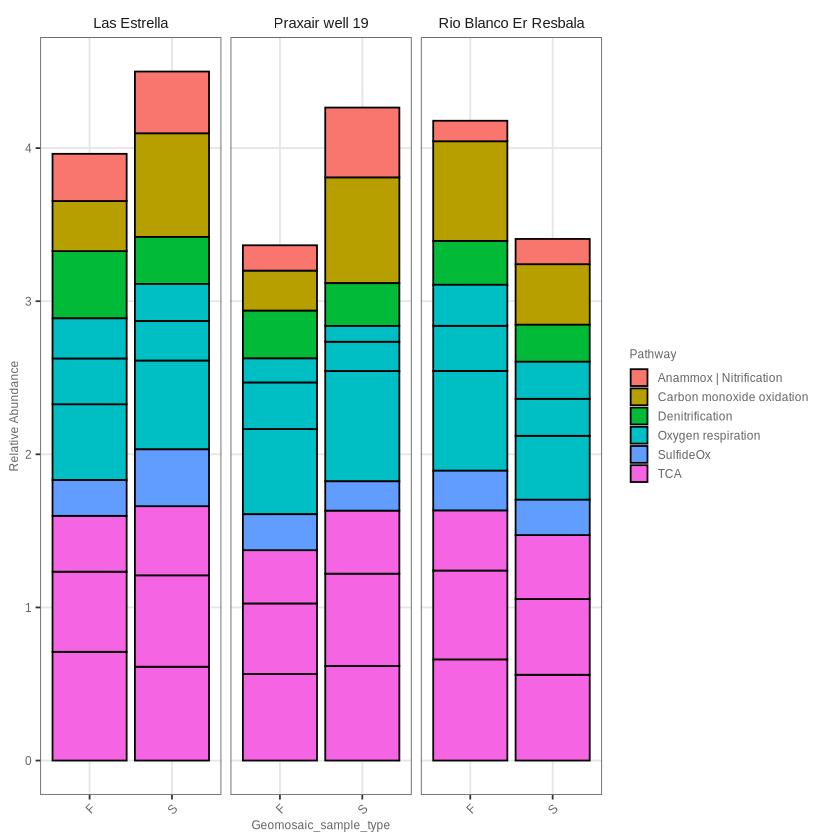

In [72]:
# 1. full table, numeric
otu <- readr::read_tsv("../tables/gm_gathering/funprofiler/raw_counts_intersect_bp.tsv", show_col_types = FALSE) %>%
  tibble::column_to_rownames("ko_id")
otu[] <- lapply(otu, as.numeric)

# 2. rpoB normalization on the FULL table
otu_rpo <- sweep(otu, 2, get_rpoB_total(otu), "/")

# 3. only now keep the biogeochemical KOs
shared <- intersect(rownames(otu_rpo), rownames(ko_annot))
phy_rpo <- phyloseq(
  otu_table(as.matrix(otu_rpo[shared, ]), taxa_are_rows = TRUE),
  tax_table(as.matrix(ko_annot[shared, ])),
  sample_data(env)
)

N <- 10

top10.genes <- sort(taxa_sums(phy_rpo), decreasing = TRUE)[1:N]
func.top10.ra <- prune_taxa(names(top10.genes), phy_rpo)

plot_bar(func.top10.ra, x = "Geomosaic_sample_type", fill="Pathway") +
  facet_grid(~site_name, scales = "free", space = "free") +
  labs(y = "Relative Abundance") +
  theme_glab() +
  theme(
    axis.text.x = element_text(angle = 45, vjust = 1, hjust = 1),
    strip.text.y = element_blank(),  # Rimuove il testo delle righe del facet_grid
    strip.background = element_blank(),  # Rimuove il box di background delle righe del facet_grid
    legend.position = "right",
    panel.grid.major = element_line(color = "grey90")
  )